# A Tour of Scientific Python

This notebook is a demo for **Notebook Minimap**. It walks through a typical
analysis workflow (signals, spectra, curve fitting, images, statistics and
simulations) using only synthetic data, so it can be shared freely.

Every section produces plots, which makes it easy to see how the minimap
shows the structure of a long notebook at a glance.

## 1 Setup

### Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy import optimize, signal, stats, ndimage

rng = np.random.default_rng(seed=42)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.3 | pandas 3.0.5


### Plot style

In [2]:
plt.rcParams.update({
    "figure.figsize": (9, 3.6),
    "figure.dpi": 100,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]

## 2 Signals

We start with a few one-dimensional signals: a sum of sines, a chirp and a
damped oscillation, each with some measurement noise.

### Generate the signals

In [3]:
fs = 1000                       # sampling rate in Hz
t = np.arange(0, 2, 1 / fs)     # two seconds

sines = np.sin(2 * np.pi * 5 * t) + 0.5 * np.sin(2 * np.pi * 23 * t)
chirp = signal.chirp(t, f0=2, t1=2, f1=60)
damped = np.exp(-1.5 * t) * np.cos(2 * np.pi * 12 * t)

noisy = {
    name: s + rng.normal(0, 0.25, t.size)
    for name, s in {"sines": sines, "chirp": chirp, "damped": damped}.items()
}
print({k: v.shape for k, v in noisy.items()})

{'sines': (2000,), 'chirp': (2000,), 'damped': (2000,)}


### Time traces

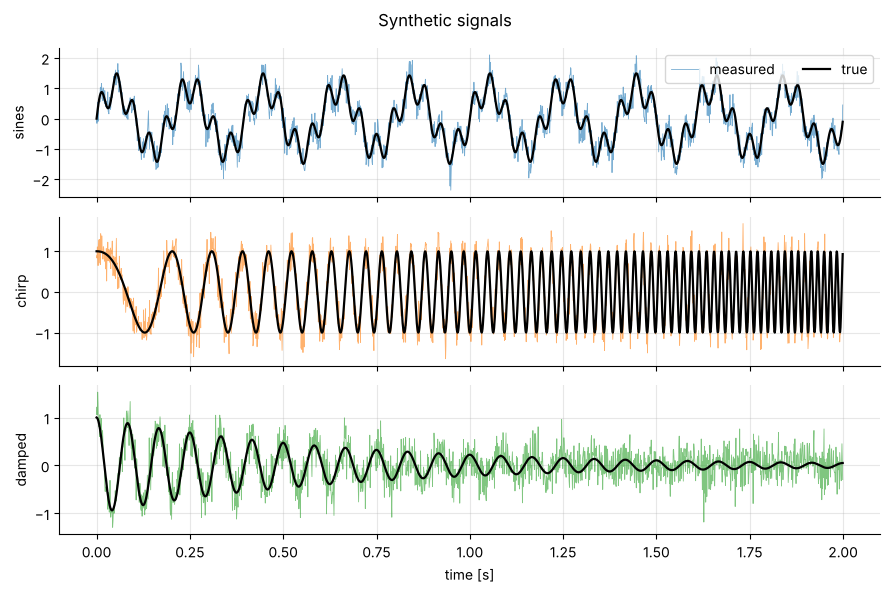

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for ax, (name, y), c in zip(axes, noisy.items(), COLORS):
    ax.plot(t, y, lw=0.6, color=c, alpha=0.6, label="measured")
    ax.plot(t, {"sines": sines, "chirp": chirp, "damped": damped}[name], lw=1.6, color="k", label="true")
    ax.set_ylabel(name)
axes[0].legend(loc="upper right", ncol=2)
axes[-1].set_xlabel("time [s]")
fig.suptitle("Synthetic signals")
plt.tight_layout()

### Noise distribution

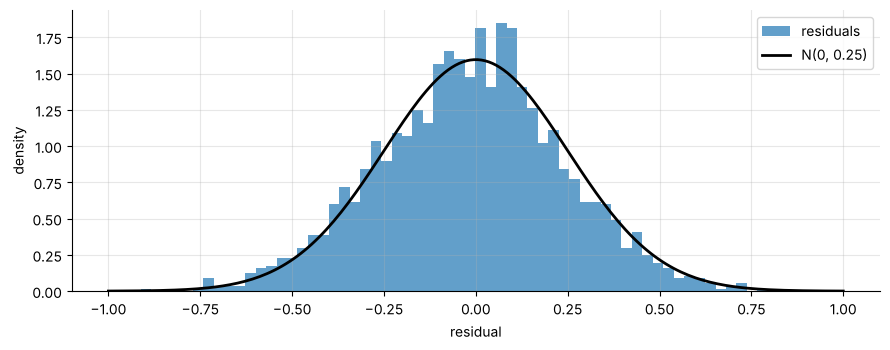

In [5]:
residual = noisy["sines"] - sines
fig, ax = plt.subplots()
ax.hist(residual, bins=60, density=True, color=COLORS[0], alpha=0.7, label="residuals")
x = np.linspace(-1, 1, 200)
ax.plot(x, stats.norm.pdf(x, 0, 0.25), "k", lw=2, label="N(0, 0.25)")
ax.set_xlabel("residual")
ax.set_ylabel("density")
ax.legend()
plt.tight_layout()

### Smoothing

A Savitzky-Golay filter removes most of the noise while keeping the peaks sharp.

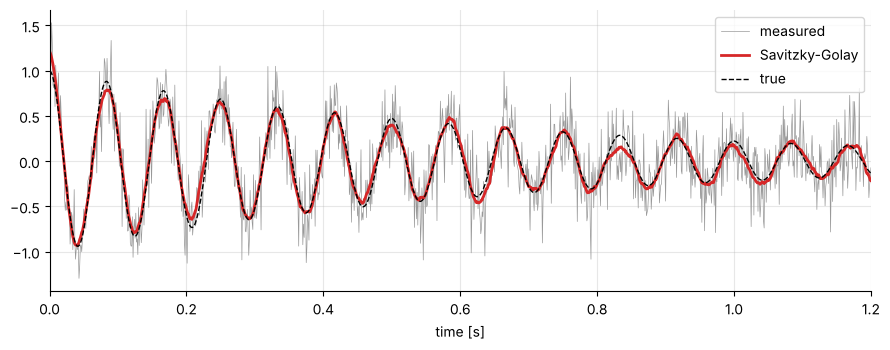

In [6]:
smooth = signal.savgol_filter(noisy["damped"], window_length=51, polyorder=3)
fig, ax = plt.subplots()
ax.plot(t, noisy["damped"], lw=0.5, color="0.6", label="measured")
ax.plot(t, smooth, lw=2, color=COLORS[3], label="Savitzky-Golay")
ax.plot(t, damped, "k--", lw=1, label="true")
ax.set_xlim(0, 1.2)
ax.set_xlabel("time [s]")
ax.legend()
plt.tight_layout()

## 3 Frequency domain

### Fourier spectra

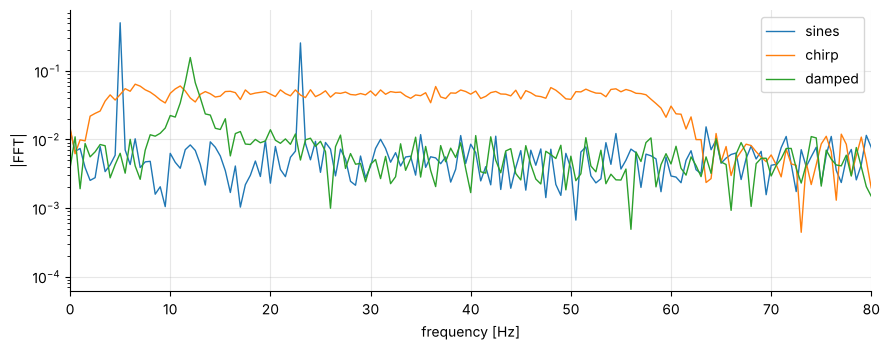

In [7]:
freqs = np.fft.rfftfreq(t.size, 1 / fs)
fig, ax = plt.subplots()
for (name, y), c in zip(noisy.items(), COLORS):
    ax.semilogy(freqs, np.abs(np.fft.rfft(y)) / t.size, lw=1, color=c, label=name)
ax.set_xlim(0, 80)
ax.set_xlabel("frequency [Hz]")
ax.set_ylabel("|FFT|")
ax.legend()
plt.tight_layout()

### Spectrogram of the chirp

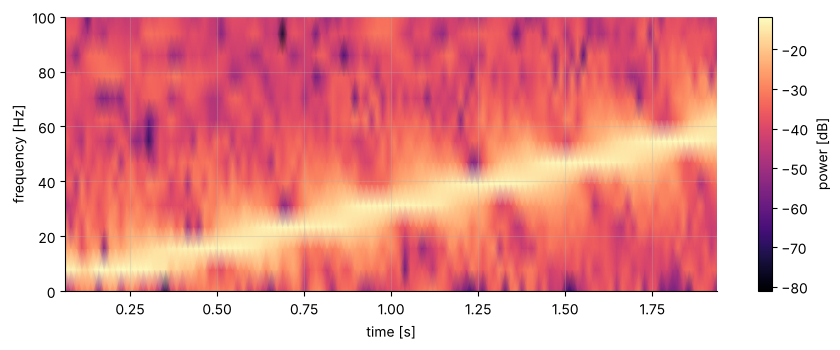

In [8]:
f, tt, Sxx = signal.spectrogram(noisy["chirp"], fs, nperseg=128, noverlap=112)
fig, ax = plt.subplots()
mesh = ax.pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading="gouraud", cmap="magma")
ax.set_ylim(0, 100)
ax.set_xlabel("time [s]")
ax.set_ylabel("frequency [Hz]")
fig.colorbar(mesh, ax=ax, label="power [dB]")
plt.tight_layout()

### Filter design

A 4th-order Butterworth low-pass filter and its frequency response.

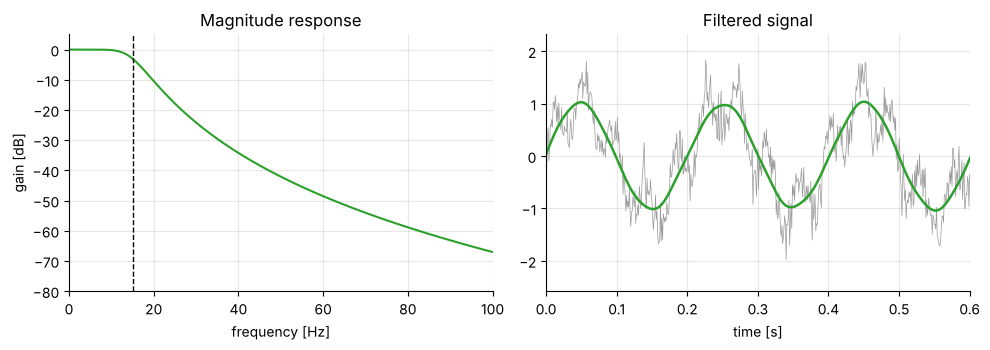

In [9]:
b, a = signal.butter(4, 15, fs=fs)
w, h = signal.freqz(b, a, fs=fs, worN=2000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
ax1.plot(w, 20 * np.log10(np.abs(h)), color=COLORS[2])
ax1.axvline(15, color="k", ls="--", lw=1)
ax1.set_xlim(0, 100)
ax1.set_ylim(-80, 5)
ax1.set_xlabel("frequency [Hz]")
ax1.set_ylabel("gain [dB]")
ax1.set_title("Magnitude response")

filtered = signal.filtfilt(b, a, noisy["sines"])
ax2.plot(t, noisy["sines"], lw=0.5, color="0.6")
ax2.plot(t, filtered, lw=1.8, color=COLORS[2])
ax2.set_xlim(0, 0.6)
ax2.set_xlabel("time [s]")
ax2.set_title("Filtered signal")
plt.tight_layout()

## 4 Spectroscopy and curve fitting

Next, a synthetic spectrum with three overlapping peaks. We fit it with a sum
of Lorentzians and of Gaussians and compare both models.

### Synthetic spectrum

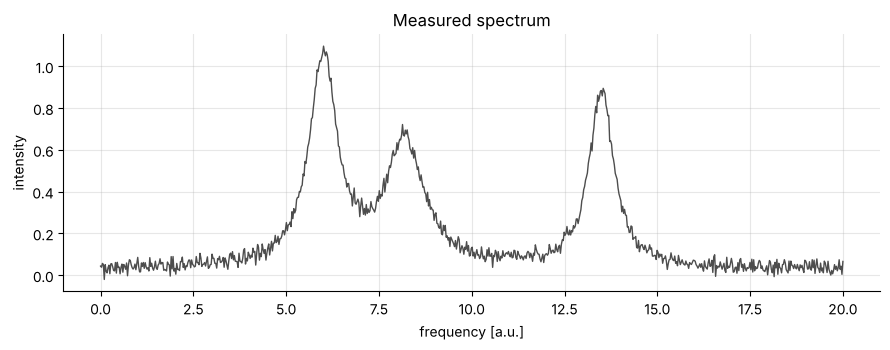

In [10]:
x = np.linspace(0, 20, 800)

def lorentz(x, a, x0, w):
    return a * w**2 / ((x - x0) ** 2 + w**2)

def gauss(x, a, x0, s):
    return a * np.exp(-0.5 * ((x - x0) / s) ** 2)

true_peaks = [(1.0, 6.0, 0.45), (0.6, 8.2, 0.6), (0.85, 13.5, 0.4)]
spectrum = sum(lorentz(x, *p) for p in true_peaks) + 0.03 + rng.normal(0, 0.02, x.size)

fig, ax = plt.subplots()
ax.plot(x, spectrum, color="0.3", lw=1)
ax.set_xlabel("frequency [a.u.]")
ax.set_ylabel("intensity")
ax.set_title("Measured spectrum")
plt.tight_layout()

### Fit with three Lorentzians

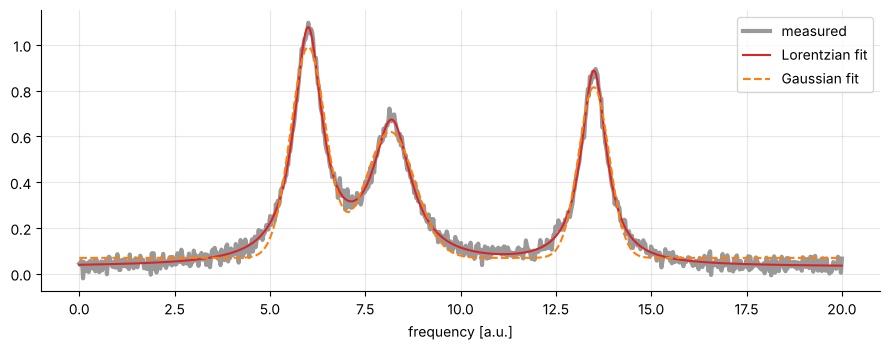

In [11]:
def multi(model):
    def f(x, offset, *p):
        return offset + sum(model(x, *p[i:i + 3]) for i in range(0, len(p), 3))
    return f

p0 = [0.0, 1, 6, 0.5, 0.5, 8, 0.5, 1, 13, 0.5]
popt_l, pcov_l = optimize.curve_fit(multi(lorentz), x, spectrum, p0=p0)
popt_g, pcov_g = optimize.curve_fit(multi(gauss), x, spectrum, p0=p0)

fig, ax = plt.subplots()
ax.plot(x, spectrum, color="0.6", lw=3, label="measured")
ax.plot(x, multi(lorentz)(x, *popt_l), color=COLORS[3], lw=1.5, label="Lorentzian fit")
ax.plot(x, multi(gauss)(x, *popt_g), color=COLORS[1], lw=1.5, ls="--", label="Gaussian fit")
ax.set_xlabel("frequency [a.u.]")
ax.legend()
plt.tight_layout()

### Individual components

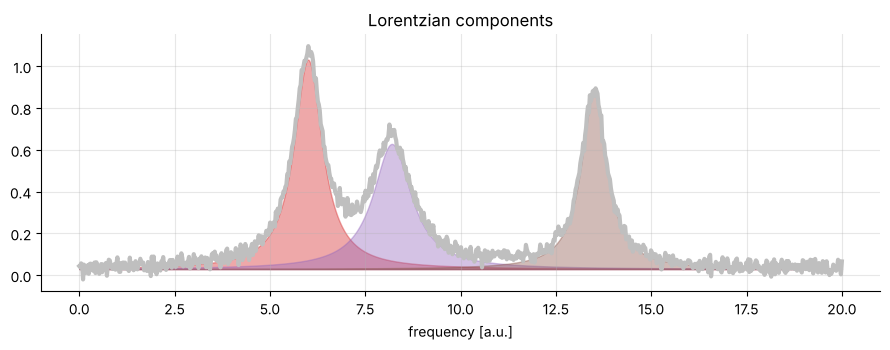

In [12]:
fig, ax = plt.subplots()
ax.plot(x, spectrum, color="0.75", lw=3)
for i, c in zip(range(1, len(popt_l), 3), COLORS[3:]):
    ax.fill_between(x, popt_l[0], popt_l[0] + lorentz(x, *popt_l[i:i + 3]), alpha=0.4, color=c)
ax.set_xlabel("frequency [a.u.]")
ax.set_title("Lorentzian components")
plt.tight_layout()

### Residuals

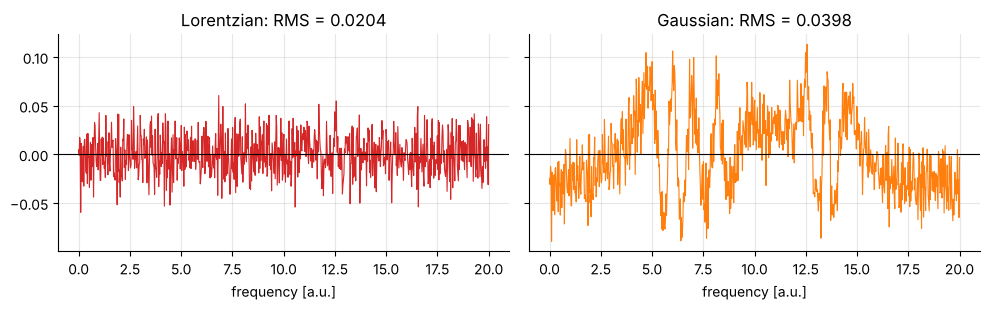

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (name, model, popt), c in zip(
    axes, [("Lorentzian", lorentz, popt_l), ("Gaussian", gauss, popt_g)], [COLORS[3], COLORS[1]]
):
    res = spectrum - multi(model)(x, *popt)
    ax.plot(x, res, lw=0.8, color=c)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{name}: RMS = {res.std():.4f}")
    ax.set_xlabel("frequency [a.u.]")
plt.tight_layout()

### Fit results

In [14]:
rows = []
for i, k in enumerate(range(1, len(popt_l), 3)):
    err = np.sqrt(np.diag(pcov_l))[k:k + 3]
    rows.append({
        "peak": i + 1,
        "amplitude": popt_l[k], "± amp": err[0],
        "center": popt_l[k + 1], "± center": err[1],
        "width": abs(popt_l[k + 2]), "± width": err[2],
        "true center": true_peaks[i][1],
    })
fit_table = pd.DataFrame(rows).set_index("peak").round(3)
fit_table

,amplitude,± amp,center,± center,width,± width,true center
peak,,,,,,,
1,1.003,0.006,6.000,0.003,0.449,0.004,6.0
2,0.599,0.005,8.198,0.005,0.608,0.008,8.2
3,0.847,0.006,13.496,0.003,0.401,0.004,13.5


### Model comparison

In [15]:
def aic(model, popt):
    rss = np.sum((spectrum - multi(model)(x, *popt)) ** 2)
    return x.size * np.log(rss / x.size) + 2 * len(popt)

print(f"AIC Lorentzian: {aic(lorentz, popt_l):9.1f}")
print(f"AIC Gaussian:   {aic(gauss, popt_g):9.1f}")
print("Lower is better: the Lorentzian model wins, as it should.")

AIC Lorentzian:   -6204.4
AIC Gaussian:     -5137.2
Lower is better: the Lorentzian model wins, as it should.


## 5 Images

Two-dimensional data: a synthetic phantom made of ellipses, the kind of test
image used in tomography.

### Phantom

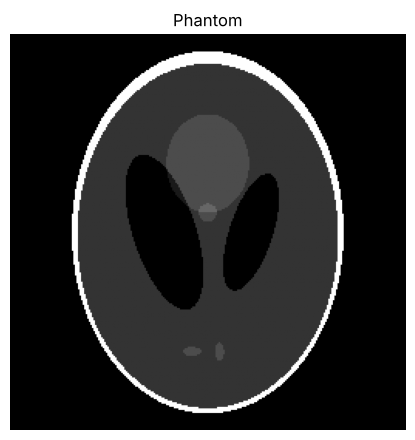

In [16]:
def phantom(n=256):
    y, x = np.mgrid[-1:1:n * 1j, -1:1:n * 1j]
    ellipses = [  # intensity, a, b, x0, y0, angle
        (1.0, 0.69, 0.92, 0, 0, 0),
        (-0.8, 0.6624, 0.874, 0, -0.0184, 0),
        (-0.2, 0.11, 0.31, 0.22, 0, -18),
        (-0.2, 0.16, 0.41, -0.22, 0, 18),
        (0.1, 0.21, 0.25, 0, 0.35, 0),
        (0.1, 0.046, 0.046, 0, 0.1, 0),
        (0.1, 0.046, 0.023, -0.08, -0.605, 0),
        (0.1, 0.023, 0.046, 0.06, -0.605, 0),
    ]
    img = np.zeros((n, n))
    for v, a, b, x0, y0, ang in ellipses:
        th = np.deg2rad(ang)
        xr = (x - x0) * np.cos(th) + (y - y0) * np.sin(th)
        yr = -(x - x0) * np.sin(th) + (y - y0) * np.cos(th)
        img[(xr / a) ** 2 + (yr / b) ** 2 <= 1] += v
    return np.flipud(img)

img = phantom()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(img, cmap="gray")
ax.set_title("Phantom")
ax.axis("off")
plt.tight_layout()

### Noise and denoising

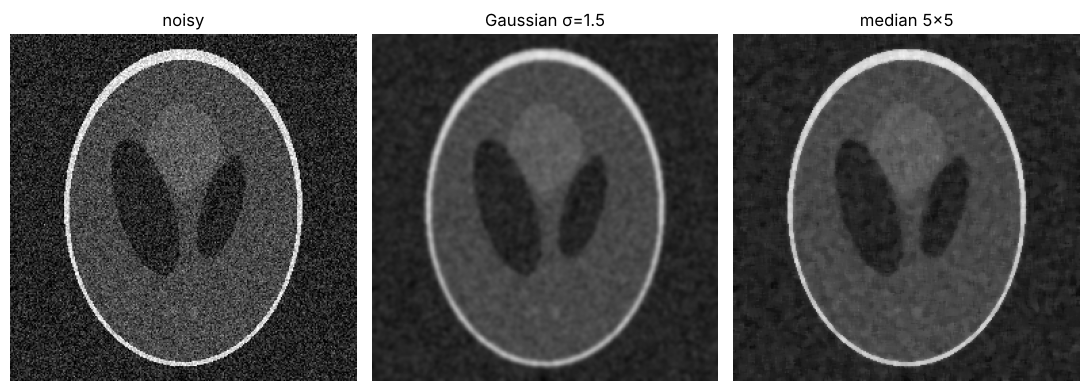

In [17]:
noisy_img = img + rng.normal(0, 0.15, img.shape)
denoised = {
    "Gaussian σ=1.5": ndimage.gaussian_filter(noisy_img, 1.5),
    "median 5×5": ndimage.median_filter(noisy_img, 5),
}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
for ax, (title, im) in zip(axes, [("noisy", noisy_img), *denoised.items()]):
    ax.imshow(im, cmap="gray", vmin=-0.2, vmax=1.2)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()

### Edges

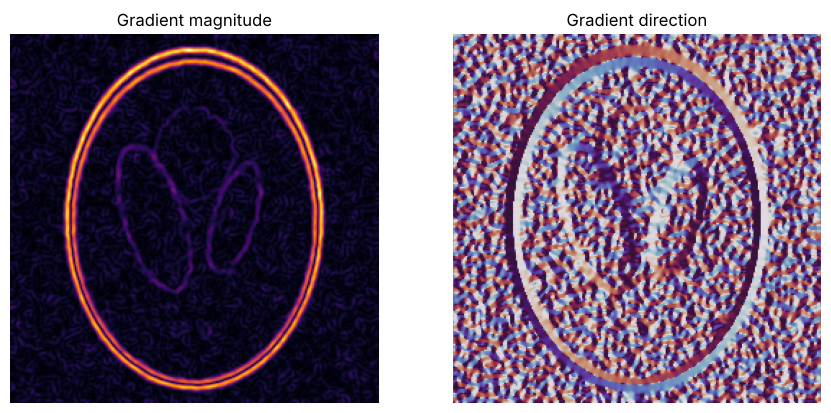

In [18]:
smooth_img = denoised["Gaussian σ=1.5"]
gx, gy = ndimage.sobel(smooth_img, 1), ndimage.sobel(smooth_img, 0)
magnitude = np.hypot(gx, gy)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
axes[0].imshow(magnitude, cmap="inferno")
axes[0].set_title("Gradient magnitude")
axes[1].imshow(np.arctan2(gy, gx), cmap="twilight")
axes[1].set_title("Gradient direction")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

### k-space

The 2D Fourier transform of the image, and a reconstruction from only the centre of k-space.

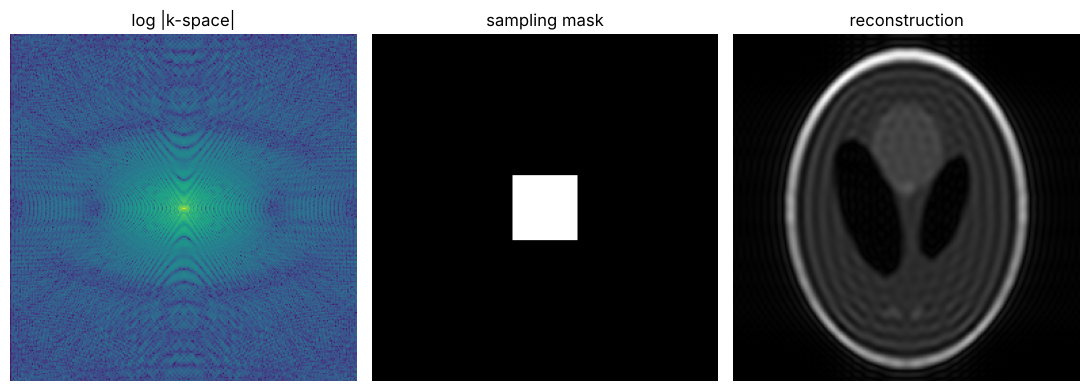

In [19]:
k = np.fft.fftshift(np.fft.fft2(img))
mask = np.zeros_like(img)
c = img.shape[0] // 2
mask[c - 24:c + 24, c - 24:c + 24] = 1
low_res = np.abs(np.fft.ifft2(np.fft.ifftshift(k * mask)))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
axes[0].imshow(np.log1p(np.abs(k)), cmap="viridis")
axes[0].set_title("log |k-space|")
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("sampling mask")
axes[2].imshow(low_res, cmap="gray")
axes[2].set_title("reconstruction")
for ax in axes:
    ax.axis("off")
plt.tight_layout()

### Line profile

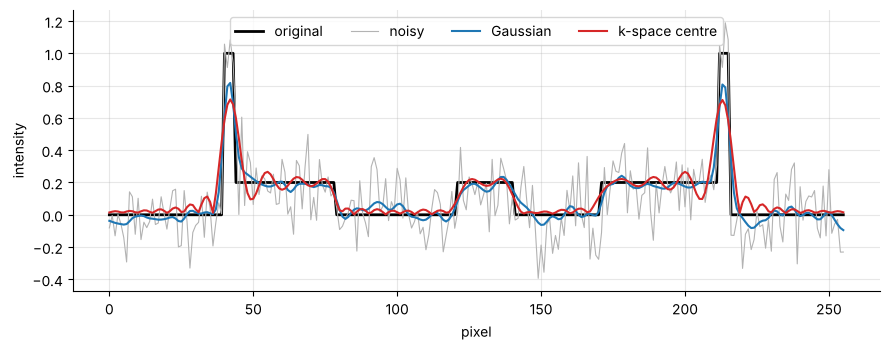

In [20]:
row = img.shape[0] // 2
fig, ax = plt.subplots()
ax.plot(img[row], "k", lw=2, label="original")
ax.plot(noisy_img[row], color="0.7", lw=0.8, label="noisy")
ax.plot(smooth_img[row], color=COLORS[0], lw=1.5, label="Gaussian")
ax.plot(low_res[row], color=COLORS[3], lw=1.5, label="k-space centre")
ax.set_xlabel("pixel")
ax.set_ylabel("intensity")
ax.legend(ncol=4, loc="upper center")
plt.tight_layout()

### Colormaps

The same image in a few perceptually uniform colormaps.

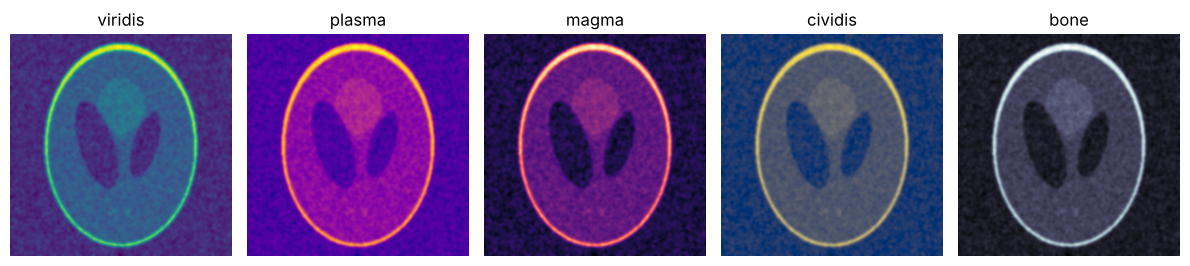

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(12, 2.8))
for ax, name in zip(axes, ["viridis", "plasma", "magma", "cividis", "bone"]):
    ax.imshow(smooth_img, cmap=name)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()

## 6 Fields and surfaces

### Contour plot

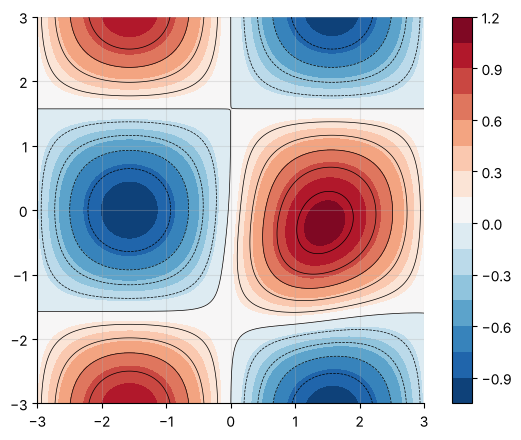

In [22]:
X, Y = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
Z = np.sin(X) * np.cos(Y) + 0.3 * np.exp(-((X - 1) ** 2 + (Y + 1) ** 2))

fig, ax = plt.subplots(figsize=(6, 4.5))
cf = ax.contourf(X, Y, Z, levels=20, cmap="RdBu_r")
ax.contour(X, Y, Z, levels=10, colors="k", linewidths=0.5)
fig.colorbar(cf, ax=ax)
ax.set_aspect("equal")
plt.tight_layout()

### Vector field

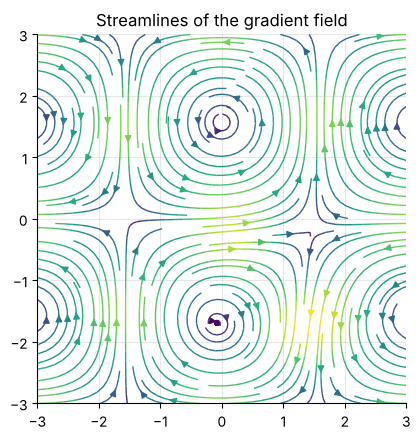

In [23]:
U, V = -np.gradient(Z, axis=0), np.gradient(Z, axis=1)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.streamplot(X, Y, V, U, color=np.hypot(U, V), cmap="viridis", density=1.4, linewidth=1)
ax.set_aspect("equal")
ax.set_title("Streamlines of the gradient field")
plt.tight_layout()

### Surface

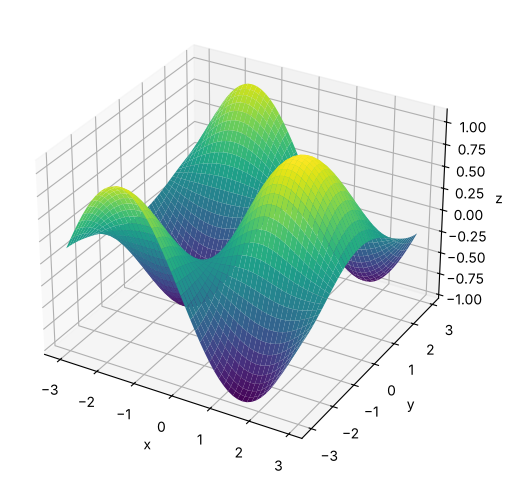

In [24]:
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
s = slice(None, None, 6)
ax.plot_surface(X[s, s], Y[s, s], Z[s, s], cmap="viridis", linewidth=0, antialiased=True)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
plt.tight_layout()

## 7 Statistics

### A synthetic dataset

In [25]:
n = 300
groups = rng.choice(["A", "B", "C"], size=n, p=[0.4, 0.35, 0.25])
dose = rng.uniform(0, 10, n)
effect = {"A": 1.0, "B": 1.6, "C": 2.3}
response = np.array([effect[g] for g in groups]) * dose + rng.normal(0, 2.5, n)
df = pd.DataFrame({"group": groups, "dose": dose.round(2), "response": response.round(2)})
df.head(8)

,group,dose,response
0,A,0.50,0.40
1,C,1.60,2.39
2,C,4.53,5.40
3,B,2.05,5.36
4,A,6.69,-0.76
5,C,2.37,7.15
6,A,7.75,9.34
7,C,2.09,6.26


### Summary statistics

In [26]:
df.groupby("group")[["dose", "response"]].describe().round(2)

dose                                           response               \
       count  mean   std   min   25%   50%   75%   max    count   mean   std   
group                                                                          
A      115.0  4.97  2.84  0.17  2.74  5.15  7.44  9.96    115.0   4.77  4.20   
B      104.0  5.20  2.89  0.10  2.58  5.22  7.68  9.85    104.0   8.33  4.84   
C       81.0  5.36  2.88  0.00  2.37  6.06  7.44  9.75     81.0  11.72  6.99   

                                        
        min   25%    50%    75%    max  
group                                   
A     -5.23  1.62   4.98   7.95  13.25  
B     -2.58  4.55   8.49  11.92  20.12  
C     -2.06  5.09  12.79  17.00  25.74

### Scatter and regression

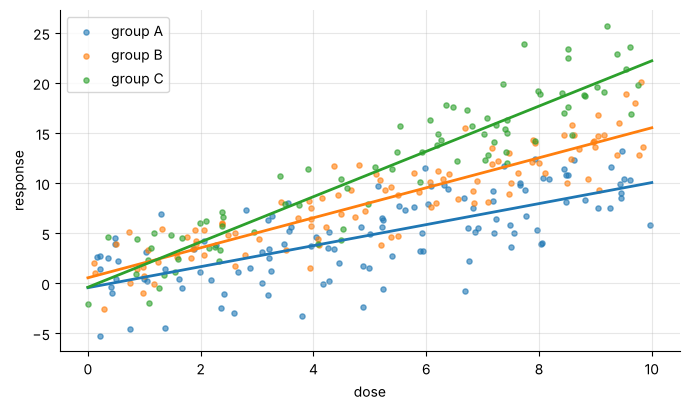

In [27]:
fig, ax = plt.subplots(figsize=(7, 4.2))
for (g, d), c in zip(df.groupby("group"), COLORS):
    ax.scatter(d.dose, d.response, s=14, alpha=0.6, color=c, label=f"group {g}")
    fit = stats.linregress(d.dose, d.response)
    xx = np.linspace(0, 10, 2)
    ax.plot(xx, fit.intercept + fit.slope * xx, color=c, lw=2)
ax.set_xlabel("dose")
ax.set_ylabel("response")
ax.legend()
plt.tight_layout()

### Distributions per group

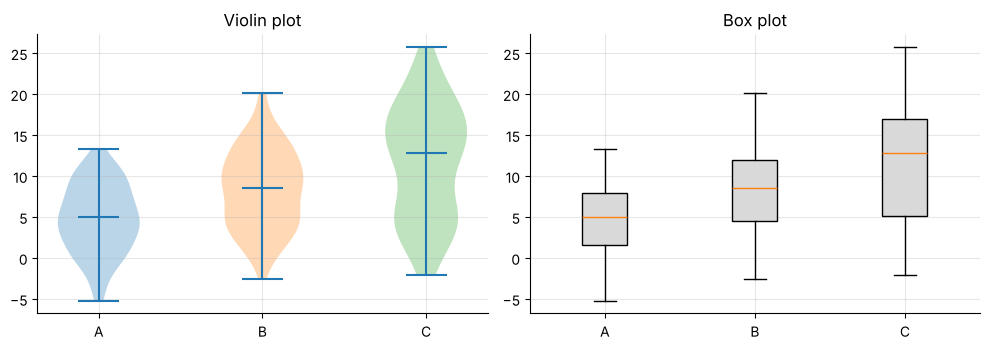

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
data = [d.response.values for _, d in df.groupby("group")]
parts = axes[0].violinplot(data, showmedians=True)
for body, c in zip(parts["bodies"], COLORS):
    body.set_facecolor(c)
axes[0].set_xticks([1, 2, 3], ["A", "B", "C"])
axes[0].set_title("Violin plot")
axes[1].boxplot(data, tick_labels=["A", "B", "C"], patch_artist=True,
                boxprops=dict(facecolor="0.85"))
axes[1].set_title("Box plot")
plt.tight_layout()

### Bootstrap

How certain is the slope of group C? We resample the data 2000 times.

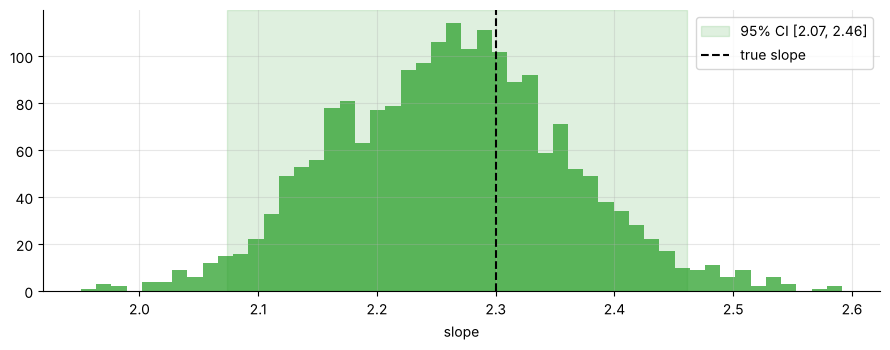

In [29]:
dc = df[df.group == "C"]
slopes = []
for _ in range(2000):
    s = dc.sample(len(dc), replace=True, random_state=rng.integers(1 << 31))
    slopes.append(stats.linregress(s.dose, s.response).slope)
slopes = np.array(slopes)
lo, hi = np.percentile(slopes, [2.5, 97.5])

fig, ax = plt.subplots()
ax.hist(slopes, bins=50, color=COLORS[2], alpha=0.75)
ax.axvspan(lo, hi, color=COLORS[2], alpha=0.15, label=f"95% CI [{lo:.2f}, {hi:.2f}]")
ax.axvline(effect["C"], color="k", ls="--", label="true slope")
ax.set_xlabel("slope")
ax.legend()
plt.tight_layout()

### Correlation matrix

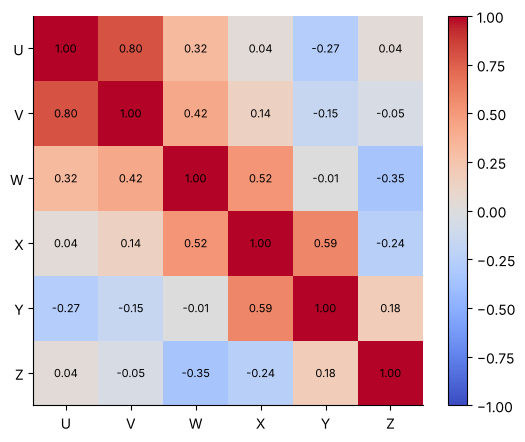

In [30]:
features = pd.DataFrame(rng.multivariate_normal(
    mean=np.zeros(6),
    cov=np.array([
        [1.0, 0.8, 0.3, 0.0, -0.2, 0.1],
        [0.8, 1.0, 0.4, 0.1, -0.1, 0.0],
        [0.3, 0.4, 1.0, 0.5, 0.0, -0.3],
        [0.0, 0.1, 0.5, 1.0, 0.6, -0.2],
        [-0.2, -0.1, 0.0, 0.6, 1.0, 0.2],
        [0.1, 0.0, -0.3, -0.2, 0.2, 1.0],
    ]),
    size=500,
), columns=list("UVWXYZ"))
corr = features.corr()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(6), corr.columns)
ax.set_yticks(range(6), corr.columns)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax)
ax.grid(False)
plt.tight_layout()

## 8 Simulations

### Random walks

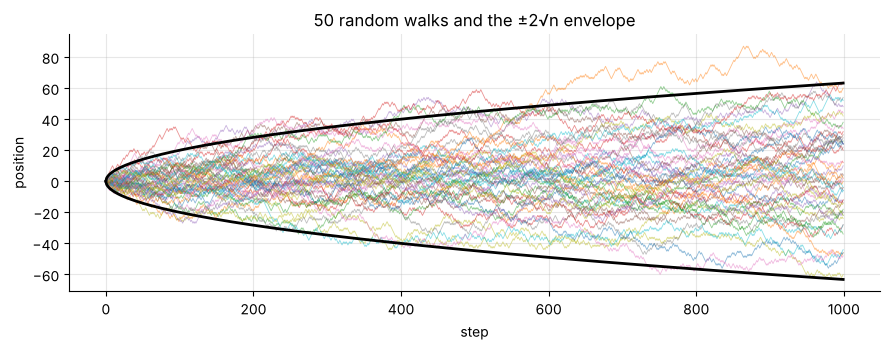

In [31]:
steps = rng.choice([-1, 1], size=(50, 1000)).cumsum(axis=1)
fig, ax = plt.subplots()
ax.plot(steps.T, lw=0.6, alpha=0.5)
envelope = 2 * np.sqrt(np.arange(1000))
ax.plot(envelope, "k", lw=2)
ax.plot(-envelope, "k", lw=2)
ax.set_xlabel("step")
ax.set_ylabel("position")
ax.set_title("50 random walks and the ±2√n envelope")
plt.tight_layout()

### Monte Carlo estimate of π

error: 0.0226


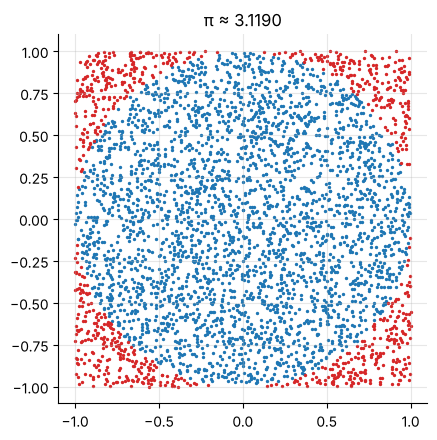

In [32]:
pts = rng.uniform(-1, 1, size=(4000, 2))
inside = (pts**2).sum(axis=1) <= 1
estimate = 4 * inside.mean()

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(*pts[inside].T, s=2, color=COLORS[0])
ax.scatter(*pts[~inside].T, s=2, color=COLORS[3])
ax.set_aspect("equal")
ax.set_title(f"π ≈ {estimate:.4f}")
plt.tight_layout()
print(f"error: {abs(estimate - np.pi):.4f}")

### Lorenz attractor

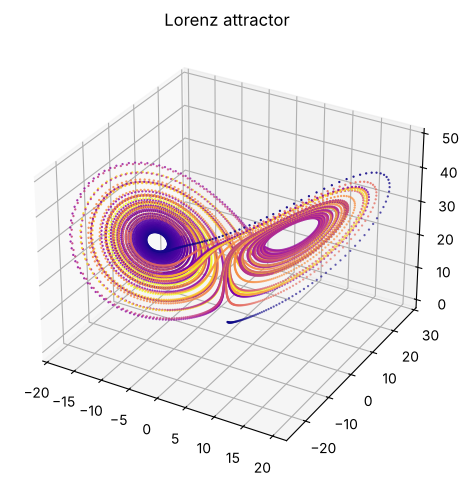

In [33]:
def lorenz(state, s=10, r=28, b=8 / 3):
    x, y, z = state
    return np.array([s * (y - x), x * (r - z) - y, x * y - b * z])

dt, n = 0.005, 12000
traj = np.empty((n, 3))
traj[0] = (0.0, 1.0, 1.05)
for i in range(n - 1):  # 4th-order Runge-Kutta
    p = traj[i]
    k1 = lorenz(p)
    k2 = lorenz(p + dt / 2 * k1)
    k3 = lorenz(p + dt / 2 * k2)
    k4 = lorenz(p + dt * k3)
    traj[i + 1] = p + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*traj.T, c=np.arange(n), cmap="plasma", s=0.4)
ax.set_title("Lorenz attractor")
plt.tight_layout()

### Pendulum phase portrait

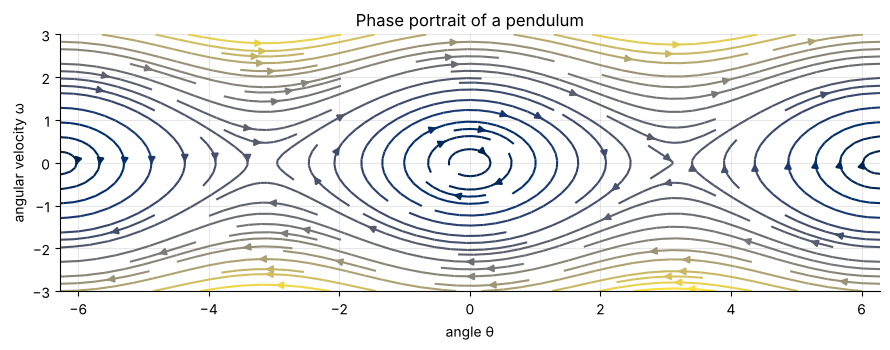

In [34]:
th, om = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 40), np.linspace(-3, 3, 30))
fig, ax = plt.subplots()
ax.streamplot(th, om, om, -np.sin(th), color=0.5 * om**2 - np.cos(th), cmap="cividis", density=1.2)
ax.set_xlabel("angle θ")
ax.set_ylabel("angular velocity ω")
ax.set_title("Phase portrait of a pendulum")
plt.tight_layout()

### Parameter sweep

Final amplitude of a driven, damped oscillator for different drive frequencies and damping.

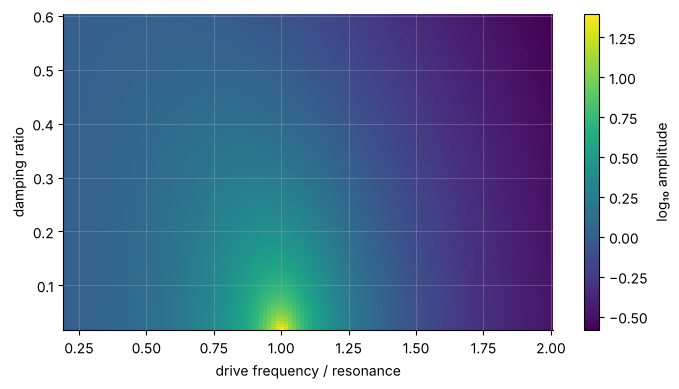

In [35]:
drive = np.linspace(0.2, 2.0, 120)
damping = np.linspace(0.02, 0.6, 100)
D, G = np.meshgrid(drive, damping)
amplitude = 1 / np.sqrt((1 - D**2) ** 2 + (2 * G * D) ** 2)

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.pcolormesh(D, G, np.log10(amplitude), cmap="viridis", shading="auto")
ax.set_xlabel("drive frequency / resonance")
ax.set_ylabel("damping ratio")
fig.colorbar(im, ax=ax, label="log₁₀ amplitude")
plt.tight_layout()

### Resonance curves

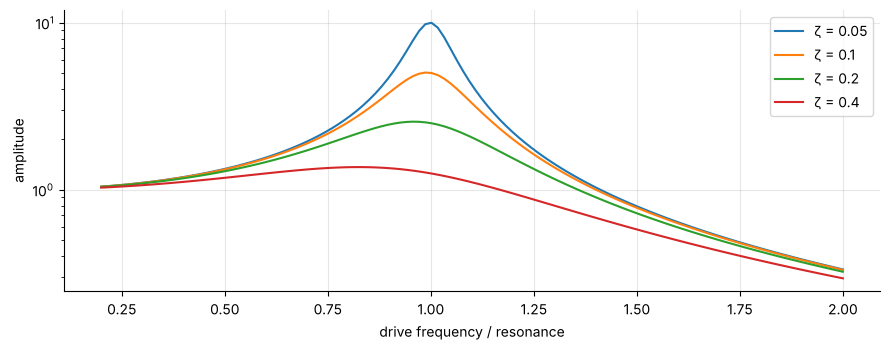

In [36]:
fig, ax = plt.subplots()
for g, c in zip([0.05, 0.1, 0.2, 0.4], COLORS):
    ax.plot(drive, 1 / np.sqrt((1 - drive**2) ** 2 + (2 * g * drive) ** 2), color=c, label=f"ζ = {g}")
ax.set_yscale("log")
ax.set_xlabel("drive frequency / resonance")
ax.set_ylabel("amplitude")
ax.legend()
plt.tight_layout()

## 9 Time series

### Seasonal data

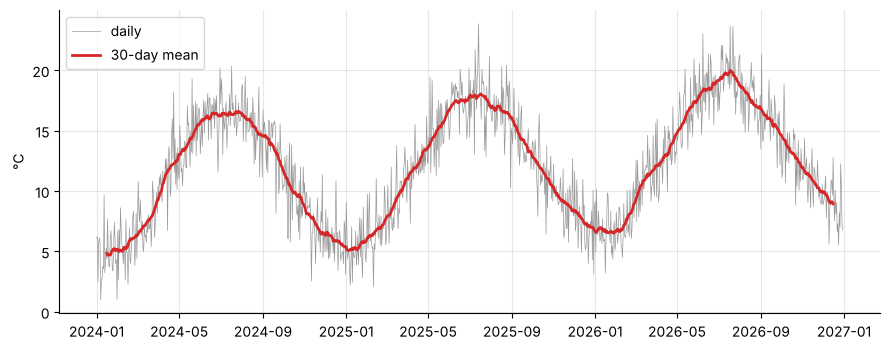

In [37]:
days = pd.date_range("2024-01-01", periods=3 * 365, freq="D")
trend = np.linspace(10, 14, days.size)
season = 6 * np.sin(2 * np.pi * (days.dayofyear - 100) / 365.25)
temperature = trend + season + rng.normal(0, 1.8, days.size)
ts = pd.Series(temperature, index=days, name="temperature")

fig, ax = plt.subplots()
ax.plot(ts, lw=0.5, color="0.6", label="daily")
ax.plot(ts.rolling(30, center=True).mean(), lw=2, color=COLORS[3], label="30-day mean")
ax.set_ylabel("°C")
ax.legend()
plt.tight_layout()

### Monthly statistics

In [38]:
monthly = ts.groupby(ts.index.month).agg(["mean", "std", "min", "max"]).round(1)
monthly.index = pd.to_datetime(monthly.index, format="%m").strftime("%b")
monthly

,mean,std,min,max
Jan,5.6,1.9,1.0,10.2
Feb,6.6,1.9,2.1,11.1
Mar,9.4,2.4,5.0,15.7
Apr,12.3,2.0,6.7,18.2
May,15.3,2.3,10.4,21.0
Jun,17.3,2.0,11.5,23.0
Jul,18.0,2.4,12.9,23.8
Aug,16.6,2.2,10.2,21.3
Sep,14.6,2.1,8.1,21.3
Oct,11.6,2.6,5.8,18.8


### Autocorrelation

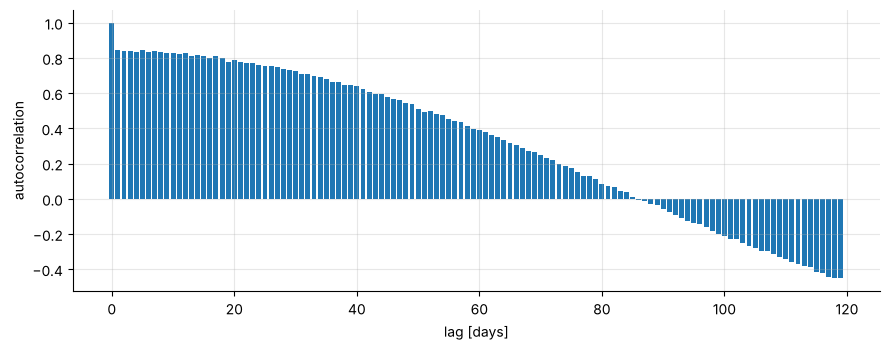

In [39]:
detrended = ts - ts.rolling(365, center=True, min_periods=1).mean()
lags = np.arange(0, 120)
acf = [detrended.autocorr(lag) for lag in lags]
fig, ax = plt.subplots()
ax.bar(lags, acf, width=0.8, color=COLORS[0])
ax.set_xlabel("lag [days]")
ax.set_ylabel("autocorrelation")
plt.tight_layout()

## 10 Summary

| Section | What we did |
|---|---|
| Signals | generated, smoothed and filtered noisy traces |
| Frequency domain | FFT, spectrogram, Butterworth filter |
| Curve fitting | Lorentzian vs. Gaussian peak models |
| Images | denoising, edges, k-space |
| Statistics | regression, bootstrap, correlations |
| Simulations | random walks, Lorenz, oscillators |
| Time series | rolling means, monthly stats, autocorrelation |

All data in this notebook is synthetic.

In [40]:
print(f"Fitted peak centres: {fit_table['center'].tolist()}")
print(f"Bootstrap 95% CI for slope C: [{lo:.2f}, {hi:.2f}]")
print(f"Monte Carlo π: {estimate:.4f}")

Fitted peak centres: [6.0, 8.198, 13.496]
Bootstrap 95% CI for slope C: [2.07, 2.46]
Monte Carlo π: 3.1190
